## INF17407 - Meta-heurísticas
## Algorítmo Grasp para o problema de roteamento de veículos
### João Vitor Soares dos Santos e Pedro Quedevez


A implementação resolve o **Problema de Roteamento de Veículos Capacitado (CVRP)** nas instâncias Augerat dos conjuntos A e B. O leitor identifica as seções do formato `.vrp`, independentemente do tamanho da instância, e extrai o ótimo conhecido do campo `COMMENT`. O GRASP combina construção gulosa aleatorizada, busca local e validação de capacidade/visitas. A distância `EUC_2D` segue o arredondamento inteiro do padrão TSPLIB.

Execute as células na ordem. As dependências necessárias (`pandas` e `matplotlib`) estão listadas em `requirements.txt`.

Os parâmetros do algoritmo são ajustáveis na célula de execução: `alfa` controla a aleatoriedade da lista restrita de candidatos e `max_iter` define o número de soluções construídas.

In [2]:
from pathlib import Path
import math
import random
import re
import time

import matplotlib.pyplot as plt
import pandas as pd

In [3]:
def encontrar_raiz_projeto():
    """Localiza a pasta que contém instancias/, mesmo com cwd dentro de codigos/."""
    for pasta in (Path.cwd(), *Path.cwd().parents):
        if (pasta / "instancias").is_dir():
            return pasta
    raise FileNotFoundError("Não encontrei a pasta 'instancias' nos diretórios-pai do notebook.")


RAIZ_PROJETO = encontrar_raiz_projeto()
PASTA_INSTANCIAS = RAIZ_PROJETO / "instancias"


def leitura_da_instancia(caminho):
    """Lê uma instância CVRP em formato TSPLIB .vrp e devolve seus dados normalizados."""
    caminho = Path(caminho)
    metadados = {}
    secoes = {}
    secao_atual = None

    with caminho.open("r", encoding="utf-8") as arquivo:
        for linha in arquivo:
            texto = linha.strip()
            if not texto:
                continue
            if texto.upper() == "EOF":
                break
            if texto.endswith("_SECTION"):
                secao_atual = texto.upper()
                secoes[secao_atual] = []
                continue
            if secao_atual is not None:
                secoes[secao_atual].append(texto.split())
            elif ":" in texto:
                chave, valor = texto.split(":", 1)
                metadados[chave.strip().upper()] = valor.strip()
            else:
                partes = texto.split(None, 1)
                if len(partes) == 2:
                    metadados[partes[0].strip().upper()] = partes[1].strip()

    if "NODE_COORD_SECTION" not in secoes or "DEMAND_SECTION" not in secoes:
        raise ValueError("A instância precisa conter NODE_COORD_SECTION e DEMAND_SECTION.")
    coordenadas = {
        int(linha[0]): (float(linha[1]), float(linha[2]))
        for linha in secoes["NODE_COORD_SECTION"] if len(linha) >= 3
    }
    demandas = {
        int(linha[0]): int(float(linha[1]))
        for linha in secoes["DEMAND_SECTION"] if len(linha) >= 2
    }
    secao_deposito = secoes.get("DEPOT_SECTION", [])
    depositos = [int(linha[0]) for linha in secao_deposito if linha and int(linha[0]) != -1]
    if not depositos:
        raise ValueError("A instância não informa o depósito em DEPOT_SECTION.")

    deposito = depositos[0]
    capacidade = int(metadados["CAPACITY"])
    nos = sorted(coordenadas)
    if set(nos) != set(demandas):
        raise ValueError("Os nós em NODE_COORD_SECTION e DEMAND_SECTION não coincidem.")
    if deposito not in coordenadas:
        raise ValueError("O depósito não está listado em NODE_COORD_SECTION.")

    correspondencia_k = re.search(r"-k(\d+)", caminho.stem, flags=re.IGNORECASE)
    numero_veiculos = int(correspondencia_k.group(1)) if correspondencia_k else math.ceil(
        sum(demandas.values()) / capacidade
    )
    comentario = metadados.get("COMMENT", "")
    correspondencia_otimo = re.search(
        r"Optimal\s+value\s*:\s*(\d+(?:\.\d+)?)", comentario, flags=re.IGNORECASE
    )
    valor_otimo = float(correspondencia_otimo.group(1)) if correspondencia_otimo else None
    if valor_otimo is not None and valor_otimo.is_integer():
        valor_otimo = int(valor_otimo)

    clientes = [no for no in nos if no != deposito]
    if any(demandas[cliente] > capacidade for cliente in clientes):
        raise ValueError("Há cliente com demanda maior que a capacidade do veículo.")
    if sum(demandas[cliente] for cliente in clientes) > numero_veiculos * capacidade:
        raise ValueError("A demanda total excede a capacidade da frota informada.")

    distancia = {}
    for origem in nos:
        distancia[origem] = {}
        for destino in nos:
            x1, y1 = coordenadas[origem]
            x2, y2 = coordenadas[destino]
            distancia[origem][destino] = int(math.hypot(x1 - x2, y1 - y2) + 0.5)

    return {
        "nome": metadados.get("NAME", caminho.stem),
        "caminho": caminho,
        "dimension": int(metadados.get("DIMENSION", len(nos))),
        "capacidade": capacidade,
        "numero_veiculos": numero_veiculos,
        "valor_otimo": valor_otimo,
        "comentario": comentario,
        "deposito": deposito,
        "coordenadas": coordenadas,
        "demandas": demandas,
        "clientes": clientes,
        "distancia": distancia,
    }


# Exemplo rápido: lê uma instância sem depender de um número fixo de linhas.
ARQUIVOS_INSTANCIAS = sorted(PASTA_INSTANCIAS.glob("conjunto-*/*.vrp"))
print(f"Raiz: {RAIZ_PROJETO}")
print(f"Instâncias encontradas: {len(ARQUIVOS_INSTANCIAS)}")
if ARQUIVOS_INSTANCIAS:
    exemplo = leitura_da_instancia(ARQUIVOS_INSTANCIAS[0])
    print(f"Exemplo: {exemplo['nome']} | clientes: {len(exemplo['clientes'])} | veículos: {exemplo['numero_veiculos']} | capacidade: {exemplo['capacidade']} | ótimo: {exemplo['valor_otimo']}")

Raiz: /home/joao/meta_heuristicas
Instâncias encontradas: 50
Exemplo: A-n32-k5 | clientes: 31 | veículos: 5 | capacidade: 100 | ótimo: 784


In [4]:
def custo_rota(rota, instancia):
    """Custo de uma rota, incluindo saída e retorno ao depósito."""
    deposito = instancia["deposito"]
    sequencia = [deposito, *rota, deposito]
    distancia = instancia["distancia"]
    return sum(distancia[a][b] for a, b in zip(sequencia, sequencia[1:]))


def funcao_objetivo(solucao, instancia):
    """Soma das distâncias de todas as rotas da solução."""
    return sum(custo_rota(rota, instancia) for rota in solucao)


def validar_solucao(solucao, instancia):
    """Retorna (válida, motivos), verificando frota, capacidade e cobertura dos clientes."""
    motivos = []
    clientes_roteados = [cliente for rota in solucao for cliente in rota]
    esperados = set(instancia["clientes"])
    if len(solucao) > instancia["numero_veiculos"]:
        motivos.append("número de rotas maior que o número de veículos")
    if len(clientes_roteados) != len(set(clientes_roteados)):
        motivos.append("há cliente visitado mais de uma vez")
    if set(clientes_roteados) != esperados:
        motivos.append("há cliente faltando ou nó inválido")
    for indice, rota in enumerate(solucao, start=1):
        carga = sum(instancia["demandas"][cliente] for cliente in rota)
        if carga > instancia["capacidade"]:
            motivos.append(f"rota {indice} excede a capacidade ({carga})")
    return not motivos, motivos

In [5]:
def _melhor_insercao(rota, cliente, instancia):
    """Retorna o menor custo incremental e a posição correspondente na rota."""
    melhor_delta = math.inf
    melhor_posicao = 0
    for posicao in range(len(rota) + 1):
        candidata = rota[:posicao] + [cliente] + rota[posicao:]
        delta = custo_rota(candidata, instancia) - custo_rota(rota, instancia)
        if delta < melhor_delta:
            melhor_delta, melhor_posicao = delta, posicao
    return melhor_delta, melhor_posicao


def _empacotamento_exato(clientes, instancia, limite_nos=250000):
    """Fallback de bin packing com backtracking para garantir uma partição viável."""
    capacidade = instancia["capacidade"]
    k = instancia["numero_veiculos"]
    demandas = instancia["demandas"]
    ordenados = sorted(clientes, key=lambda cliente: demandas[cliente], reverse=True)
    rotas = [[] for _ in range(k)]
    cargas = [0] * k
    estados_falhos = set()
    nos_visitados = [0]

    def alocar(indice):
        nos_visitados[0] += 1
        if nos_visitados[0] > limite_nos:
            return False
        if indice == len(ordenados):
            return True
        estado = (indice, tuple(sorted(cargas, reverse=True)))
        if estado in estados_falhos:
            return False
        cliente = ordenados[indice]
        demanda = demandas[cliente]
        cargas_ja_testadas = set()
        for veiculo in sorted(range(k), key=lambda i: cargas[i], reverse=True):
            if cargas[veiculo] in cargas_ja_testadas:
                continue
            cargas_ja_testadas.add(cargas[veiculo])
            if cargas[veiculo] + demanda <= capacidade:
                cargas[veiculo] += demanda
                rotas[veiculo].append(cliente)
                if alocar(indice + 1):
                    return True
                rotas[veiculo].pop()
                cargas[veiculo] -= demanda
                if cargas[veiculo] == 0:
                    break
        estados_falhos.add(estado)
        return False

    if not alocar(0):
        raise RuntimeError(
            "Não foi possível encontrar uma partição viável dentro do limite de busca; "
            "verifique capacidade, número de veículos e demanda total."
        )

    # Ordena cada rota por inserção de menor custo para iniciar a busca local.
    rotas_ordenadas = []
    for rota in rotas:
        ordem = []
        for cliente in rota:
            _, posicao = _melhor_insercao(ordem, cliente, instancia)
            ordem.insert(posicao, cliente)
        if ordem:
            rotas_ordenadas.append(ordem)
    return rotas_ordenadas


def algoritmo_construtivo(alfa, instancia, rng):
    """Construção gulosa aleatorizada por inserção, com partição viável de fallback."""
    if not 0 <= alfa <= 1:
        raise ValueError("alfa deve estar entre 0 e 1.")
    k = instancia["numero_veiculos"]
    capacidade = instancia["capacidade"]
    demandas = instancia["demandas"]
    rotas = [[] for _ in range(k)]
    cargas = [0] * k
    restantes = sorted(instancia["clientes"], key=lambda c: demandas[c], reverse=True)

    while restantes:
        # Escolhe aleatoriamente entre até três clientes de maior demanda,
        # reduzindo a chance de deixar um cliente grande sem espaço no final.
        candidatos_clientes = restantes[:min(3, len(restantes))]
        cliente = rng.choice(candidatos_clientes)
        candidatos = []
        for veiculo, rota in enumerate(rotas):
            if cargas[veiculo] + demandas[cliente] <= capacidade:
                delta, posicao = _melhor_insercao(rota, cliente, instancia)
                candidatos.append((delta, veiculo, posicao))

        if not candidatos:
            return _empacotamento_exato(instancia["clientes"], instancia)

        menor = min(c[0] for c in candidatos)
        maior = max(c[0] for c in candidatos)
        limite_rcl = menor + alfa * (maior - menor)
        rcl = [c for c in candidatos if c[0] <= limite_rcl]
        _, veiculo, posicao = rng.choice(rcl)
        rotas[veiculo].insert(posicao, cliente)
        cargas[veiculo] += demandas[cliente]
        restantes.remove(cliente)

    return [rota for rota in rotas if rota]

In [6]:
def busca_local(solucao, instancia, max_movimentos=100):
    """Busca local best-improvement: 2-opt, realocação e troca de clientes."""
    k = instancia["numero_veiculos"]
    rotas = [rota[:] for rota in solucao]
    rotas.extend([[] for _ in range(k - len(rotas))])
    demandas = instancia["demandas"]
    capacidade = instancia["capacidade"]

    for _ in range(max_movimentos):
        custos = [custo_rota(rota, instancia) for rota in rotas]
        melhor_delta = 0
        melhor_movimento = None

        # 2-opt: reverte um trecho dentro da mesma rota.
        for i, rota in enumerate(rotas):
            for inicio in range(len(rota) - 1):
                for fim in range(inicio + 1, len(rota)):
                    nova = rota[:inicio] + list(reversed(rota[inicio:fim + 1])) + rota[fim + 1:]
                    delta = custo_rota(nova, instancia) - custos[i]
                    if delta < melhor_delta:
                        melhor_delta = delta
                        melhor_movimento = ("rota", i, nova)

        # Realocação dentro de uma rota ou entre duas rotas.
        cargas = [sum(demandas[c] for c in rota) for rota in rotas]
        for origem, rota_origem in enumerate(rotas):
            for indice, cliente in enumerate(rota_origem):
                sem_cliente = rota_origem[:indice] + rota_origem[indice + 1:]
                for destino, rota_destino in enumerate(rotas):
                    if destino != origem and cargas[destino] + demandas[cliente] > capacidade:
                        continue
                    base_destino = sem_cliente if destino == origem else rota_destino
                    for posicao in range(len(base_destino) + 1):
                        nova_destino = base_destino[:posicao] + [cliente] + base_destino[posicao:]
                        if destino == origem:
                            if nova_destino == rota_origem:
                                continue
                            delta = custo_rota(nova_destino, instancia) - custos[origem]
                            movimento = ("rota", origem, nova_destino)
                        else:
                            delta = (custo_rota(sem_cliente, instancia)
                                     + custo_rota(nova_destino, instancia)
                                     - custos[origem] - custos[destino])
                            movimento = ("duas_rotas", origem, destino, sem_cliente, nova_destino)
                        if delta < melhor_delta:
                            melhor_delta = delta
                            melhor_movimento = movimento

        # Troca de clientes entre rotas, preservando a capacidade dos veículos.
        for i in range(len(rotas)):
            for j in range(i + 1, len(rotas)):
                for pos_i, cliente_i in enumerate(rotas[i]):
                    for pos_j, cliente_j in enumerate(rotas[j]):
                        nova_carga_i = cargas[i] - demandas[cliente_i] + demandas[cliente_j]
                        nova_carga_j = cargas[j] - demandas[cliente_j] + demandas[cliente_i]
                        if nova_carga_i > capacidade or nova_carga_j > capacidade:
                            continue
                        nova_i, nova_j = rotas[i][:], rotas[j][:]
                        nova_i[pos_i], nova_j[pos_j] = cliente_j, cliente_i
                        delta = (custo_rota(nova_i, instancia) + custo_rota(nova_j, instancia)
                                 - custos[i] - custos[j])
                        if delta < melhor_delta:
                            melhor_delta = delta
                            melhor_movimento = ("duas_rotas", i, j, nova_i, nova_j)

        if melhor_movimento is None:
            break
        if melhor_movimento[0] == "rota":
            _, indice, nova_rota = melhor_movimento
            rotas[indice] = nova_rota
        else:
            _, i, j, nova_i, nova_j = melhor_movimento
            rotas[i], rotas[j] = nova_i, nova_j

    return [rota for rota in rotas if rota]

In [7]:
def grasp(instancia, alfa=0.2, max_iter=100, seed=None, max_movimentos_local=100):
    """Executa o GRASP e devolve a melhor solução viável encontrada."""
    if max_iter < 1:
        raise ValueError("max_iter deve ser pelo menos 1.")
    rng = random.Random(seed)
    inicio = time.perf_counter()
    melhor_solucao = None
    melhor_custo = math.inf
    melhor_iteracao = None

    for iteracao in range(1, max_iter + 1):
        solucao = algoritmo_construtivo(alfa, instancia, rng)
        solucao = busca_local(solucao, instancia, max_movimentos=max_movimentos_local)
        valida, motivos = validar_solucao(solucao, instancia)
        if not valida:
            raise RuntimeError("A construção/local search gerou solução inválida: " + "; ".join(motivos))
        custo = funcao_objetivo(solucao, instancia)
        if custo < melhor_custo:
            melhor_solucao = [rota[:] for rota in solucao]
            melhor_custo = custo
            melhor_iteracao = iteracao

    return {
        "rotas": melhor_solucao,
        "custo": melhor_custo,
        "iteracao": melhor_iteracao,
        "tempo_segundos": time.perf_counter() - inicio,
        "valida": validar_solucao(melhor_solucao, instancia)[0],
    }


def formatar_solucao(resultado, instancia):
    """Exibe as rotas com o depósito explícito no início e no fim."""
    deposito = instancia["deposito"]
    return [
        [deposito, *rota, deposito]
        for rota in resultado["rotas"]
    ]

In [8]:
def resolver_instancia(caminho, alfa=0.2, max_iter=100, seed=42, max_movimentos_local=100):
    """Lê e resolve um arquivo .vrp, validando a solução antes de retorná-la."""
    instancia = leitura_da_instancia(caminho)
    resultado = grasp(
        instancia,
        alfa=alfa,
        max_iter=max_iter,
        seed=seed,
        max_movimentos_local=max_movimentos_local,
    )
    resultado["instancia"] = instancia
    return resultado


def listar_instancias(conjuntos=("conjunto-A", "conjunto-B")):
    """Lista arquivos .vrp de um ou dos dois conjuntos."""
    arquivos = []
    for conjunto in conjuntos:
        arquivos.extend((PASTA_INSTANCIAS / conjunto).glob("*.vrp"))
    return sorted(arquivos)


def executar_todas(conjuntos=("conjunto-A", "conjunto-B"), alfa=0.2,
                    max_iter=30, seed=42, max_movimentos_local=50):
    """Resolve em lote as instâncias escolhidas e retorna um DataFrame de resultados."""
    registros = []
    for indice, caminho in enumerate(listar_instancias(conjuntos)):
        resultado = resolver_instancia(
            caminho,
            alfa=alfa,
            max_iter=max_iter,
            seed=seed + indice,
            max_movimentos_local=max_movimentos_local,
        )
        instancia = resultado["instancia"]
        registros.append({
            "instancia": instancia["nome"],
            "conjunto": caminho.parent.name,
            "clientes": len(instancia["clientes"]),
            "veiculos": instancia["numero_veiculos"],
            "custo": resultado["custo"],
            "rotas": len(resultado["rotas"]),
            "valida": resultado["valida"],
            "iteracao_melhor": resultado["iteracao"],
            "tempo_segundos": resultado["tempo_segundos"],
        })
    return pd.DataFrame(registros)


# Demonstração com a primeira instância encontrada. Altere o caminho para escolher outra.
resultado_exemplo = resolver_instancia(
    ARQUIVOS_INSTANCIAS[0], alfa=0.2, max_iter=30, seed=42, max_movimentos_local=50
)
print(f"Instância: {resultado_exemplo['instancia']['nome']}")
print(f"Custo total: {resultado_exemplo['custo']}")
print(f"Solução viável: {resultado_exemplo['valida']}")
for numero, rota in enumerate(formatar_solucao(resultado_exemplo, resultado_exemplo["instancia"]), start=1):
    carga = sum(resultado_exemplo["instancia"]["demandas"][cliente] for cliente in rota[1:-1])
    print(f"Rota {numero}: {rota} | carga = {carga}")

Instância: A-n32-k5
Custo total: 816
Solução viável: True
Rota 1: [1, 15, 7, 3, 4, 24, 5, 12, 23, 30, 21, 1] | carga = 97
Rota 2: [1, 27, 8, 14, 18, 20, 32, 22, 1] | carga = 98
Rota 3: [1, 25, 28, 1] | carga = 44
Rota 4: [1, 13, 2, 17, 31, 1] | carga = 72
Rota 5: [1, 6, 26, 11, 16, 10, 19, 9, 29, 1] | carga = 99


## Comparação: GRASP clássico e Reactive GRASP

A célula a seguir compara o GRASP clássico com alfa fixo (`0.0`, `0.25`, `0.5`, `0.75` e `1.0`) e o **Reactive GRASP**, que começa testando todos esses alfas e atualiza suas probabilidades de seleção em blocos de iterações, conforme o pseudocódigo. O código salva a tabela CSV e o gráfico PNG; a célula seguinte também mostra o gráfico no notebook.

Para uma primeira execução rápida, foram definidos apenas **3 iterações** e **3 movimentos de busca local**. Aumente esses parâmetros para experimentos mais robustos.

In [13]:
ALFAS_COMPARACAO = (0.0, 0.25, 0.5, 0.75, 1.0)


def grasp_reativo(instancia, alfas=ALFAS_COMPARACAO, max_iter=3,
                  block_iterations=2, delta=5.0, seed=42,
                  max_movimentos_local=3):
    """Reactive GRASP: atualiza probabilidades de alfa a cada bloco de iterações."""
    if not alfas or any(not 0 <= alfa <= 1 for alfa in alfas):
        raise ValueError("Informe alfas entre 0 e 1.")
    if max_iter < 1 or block_iterations < 1 or delta <= 0:
        raise ValueError("max_iter e block_iterations devem ser positivos; delta também.")

    rng = random.Random(seed)
    inicio = time.perf_counter()
    melhor_solucao = None
    melhor_custo = math.inf
    melhor_iteracao = None
    medias_custo = {}
    bloco = []
    contagens_alfa = {alfa: 0 for alfa in alfas}

    # Inicialização: constrói e melhora uma solução para cada alfa.
    for alfa in alfas:
        solucao = algoritmo_construtivo(alfa, instancia, rng)
        solucao = busca_local(solucao, instancia, max_movimentos=max_movimentos_local)
        valida, motivos = validar_solucao(solucao, instancia)
        if not valida:
            raise RuntimeError("Solução inicial inviável: " + "; ".join(motivos))
        custo = funcao_objetivo(solucao, instancia)
        medias_custo[alfa] = float(custo)
        bloco.append((alfa, custo))
        if custo < melhor_custo:
            melhor_solucao = [rota[:] for rota in solucao]
            melhor_custo = custo
            melhor_iteracao = f"inicialização (alfa={alfa:g})"

    def calcular_probabilidades(custos_por_alfa):
        # Para minimização, alfas com menor custo médio recebem mais probabilidade.
        log_pesos = {
            alfa: -delta * math.log(max(custos_por_alfa[alfa] / melhor_custo, 1.0))
            for alfa in alfas
        }
        maior_log_peso = max(log_pesos.values())
        pesos = {alfa: math.exp(log_pesos[alfa] - maior_log_peso) for alfa in alfas}
        soma_pesos = sum(pesos.values())
        return {alfa: pesos[alfa] / soma_pesos for alfa in alfas}

    probabilidades = calcular_probabilidades(medias_custo)
    bloco = []

    for iteracao in range(1, max_iter + 1):
        # Ao fim de cada bloco, atualiza os custos médios observados e as probabilidades.
        if iteracao > 1 and (iteracao - 1) % block_iterations == 0:
            custos_bloco = {alfa: [] for alfa in alfas}
            for alfa_observado, custo_observado in bloco:
                custos_bloco[alfa_observado].append(custo_observado)
            for alfa in alfas:
                if custos_bloco[alfa]:
                    medias_custo[alfa] = sum(custos_bloco[alfa]) / len(custos_bloco[alfa])
            probabilidades = calcular_probabilidades(medias_custo)
            bloco = []

        alfa = rng.choices(alfas, weights=[probabilidades[a] for a in alfas], k=1)[0]
        solucao = algoritmo_construtivo(alfa, instancia, rng)
        solucao = busca_local(solucao, instancia, max_movimentos=max_movimentos_local)
        valida, motivos = validar_solucao(solucao, instancia)
        if not valida:
            raise RuntimeError("Solução reativa inviável: " + "; ".join(motivos))
        custo = funcao_objetivo(solucao, instancia)
        bloco.append((alfa, custo))
        contagens_alfa[alfa] += 1
        if custo < melhor_custo:
            melhor_solucao = [rota[:] for rota in solucao]
            melhor_custo = custo
            melhor_iteracao = iteracao

    return {
        "rotas": melhor_solucao,
        "custo": melhor_custo,
        "iteracao": melhor_iteracao,
        "tempo_segundos": time.perf_counter() - inicio,
        "valida": validar_solucao(melhor_solucao, instancia)[0],
        "probabilidades_finais": probabilidades,
        "contagens_alfa": contagens_alfa,
    }


def executar_comparacao_alphas(conjuntos=("conjunto-A", "conjunto-B"),
                                alfas=ALFAS_COMPARACAO, max_iter=3,
                                seed=42, max_movimentos_local=3,
                                block_iterations=2, delta=5.0):
    """Compara GRASP clássico para cada alfa e Reactive GRASP em todas as instâncias."""
    if not alfas:
        raise ValueError("Informe pelo menos um valor de alfa.")
    if any(not 0 <= alfa <= 1 for alfa in alfas):
        raise ValueError("Todos os valores de alfa devem estar entre 0 e 1.")

    arquivos = listar_instancias(conjuntos)
    registros = []
    for indice, caminho in enumerate(arquivos):
        instancia = leitura_da_instancia(caminho)
        if instancia["valor_otimo"] is None:
            raise ValueError(
                f"A instância {caminho.name} não possui 'Optimal value' no COMMENT."
            )

        # GRASP clássico: cada execução usa um alfa fixo.
        for alfa in alfas:
            resultado = grasp(
                instancia,
                alfa=alfa,
                max_iter=max_iter,
                seed=seed + indice,
                max_movimentos_local=max_movimentos_local,
            )
            if not resultado["valida"]:
                raise RuntimeError(f"Solução inviável para {caminho.name}, alfa={alfa}.")
            registros.append({
                "instancia": instancia["nome"],
                "conjunto": caminho.parent.name,
                "metodo": f"GRASP alfa={alfa:g}",
                "alfa": alfa,
                "otimo": instancia["valor_otimo"],
                "custo_grasp": resultado["custo"],
                "gap_percentual": (resultado["custo"] / instancia["valor_otimo"] - 1) * 100,
                "tempo_segundos": resultado["tempo_segundos"],
                "valida": resultado["valida"],
            })

        # Reactive GRASP: escolhe alfa de forma probabilística e atualiza por blocos.
        resultado_reativo = grasp_reativo(
            instancia,
            alfas=alfas,
            max_iter=max_iter,
            block_iterations=block_iterations,
            delta=delta,
            seed=seed + indice,
            max_movimentos_local=max_movimentos_local,
        )
        registros.append({
            "instancia": instancia["nome"],
            "conjunto": caminho.parent.name,
            "metodo": "Reactive GRASP",
            "alfa": None,
            "otimo": instancia["valor_otimo"],
            "custo_grasp": resultado_reativo["custo"],
            "gap_percentual": (resultado_reativo["custo"] / instancia["valor_otimo"] - 1) * 100,
            "tempo_segundos": resultado_reativo["tempo_segundos"],
            "valida": resultado_reativo["valida"],
        })
    return pd.DataFrame(registros)


def salvar_grafico_comparacao(resultados, caminho_saida=None):
    """Salva gráficos de custos por instância, comparando GRASP clássico e reativo."""
    if resultados.empty:
        raise ValueError("Não há resultados para plotar.")
    if caminho_saida is None:
        caminho_saida = RAIZ_PROJETO / "codigos" / "comparacao_otimo_grasp.png"
    caminho_saida = Path(caminho_saida)
    caminho_saida.parent.mkdir(parents=True, exist_ok=True)

    grupos = sorted(resultados["conjunto"].unique())
    fig, eixos = plt.subplots(
        len(grupos), 1,
        figsize=(max(18, len(resultados["instancia"].unique()) * 0.65), 9 * len(grupos)),
        squeeze=False,
    )
    metodos = [f"GRASP alfa={alfa:g}" for alfa in sorted(resultados["alfa"].dropna().unique())]
    metodos.append("Reactive GRASP")
    largura = 0.8 / len(metodos)

    for eixo, conjunto in zip(eixos[:, 0], grupos):
        dados = resultados[resultados["conjunto"] == conjunto]
        instancias = sorted(dados["instancia"].unique())
        posicoes = list(range(len(instancias)))
        otimos = [
            dados.loc[dados["instancia"] == nome, "otimo"].iloc[0]
            for nome in instancias
        ]
        eixo.plot(
            posicoes, otimos, color="black", marker="o", linestyle="--",
            linewidth=2, label="Ótimo conhecido", zorder=5,
        )
        for indice_metodo, metodo in enumerate(metodos):
            custos = [
                dados.loc[
                    (dados["instancia"] == nome) & (dados["metodo"] == metodo),
                    "custo_grasp",
                ].iloc[0]
                for nome in instancias
            ]
            deslocamentos = [
                posicao - 0.4 + largura * (indice_metodo + 0.5)
                for posicao in posicoes
            ]
            eixo.bar(deslocamentos, custos, width=largura, label=metodo)

        eixo.set_title(conjunto)
        eixo.set_ylabel("Custo da solução")
        eixo.set_xticks(posicoes)
        eixo.set_xticklabels(instancias, rotation=75, ha="right", fontsize=8)
        eixo.grid(axis="y", linestyle=":", alpha=0.5)
        eixo.legend(ncol=3, fontsize=9)

    eixos[-1, 0].set_xlabel("Instância")
    fig.suptitle("Ótimo conhecido vs. GRASP clássico e Reactive GRASP", fontsize=15)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(caminho_saida, dpi=180, bbox_inches="tight")
    plt.close(fig)
    return caminho_saida


# Parâmetros pequenos para uma primeira comparação rápida (ajuste para experimentos finais).
ITERACOES_COMPARACAO = 50
MOVIMENTOS_BUSCA_LOCAL = 20
resultados_alphas = executar_comparacao_alphas(
    conjuntos=("conjunto-A", "conjunto-B"),
    alfas=ALFAS_COMPARACAO,
    max_iter=ITERACOES_COMPARACAO,
    seed=42,
    max_movimentos_local=MOVIMENTOS_BUSCA_LOCAL,
    block_iterations=2,
    delta=5.0,
)
assert resultados_alphas["valida"].all(), "Uma ou mais soluções não são viáveis."

arquivo_csv = RAIZ_PROJETO / "codigos" / "resultados_comparacao_grasp.csv"
resultados_alphas.to_csv(arquivo_csv, index=False)
arquivo_grafico = salvar_grafico_comparacao(resultados_alphas)
print(f"Execuções: {len(resultados_alphas)} linhas de resultados")
print(f"Iterações GRASP: {ITERACOES_COMPARACAO}; movimentos de busca local: {MOVIMENTOS_BUSCA_LOCAL}")
print(f"Resultados CSV: {arquivo_csv}")
print(f"Gráfico PNG: {arquivo_grafico}")
resultados_alphas.sort_values(["conjunto", "instancia", "metodo"]).reset_index(drop=True)

Execuções: 300 linhas de resultados
Iterações GRASP: 50; movimentos de busca local: 20
Resultados CSV: /home/joao/meta_heuristicas/codigos/resultados_comparacao_grasp.csv
Gráfico PNG: /home/joao/meta_heuristicas/codigos/comparacao_otimo_grasp.png


,instancia,conjunto,metodo,alfa,otimo,custo_grasp,gap_percentual,tempo_segundos,valida
0,A-n32-k5,conjunto-A,GRASP alfa=0,0.00,784,808,3.061224,2.195534,True
1,A-n32-k5,conjunto-A,GRASP alfa=0.25,0.25,784,818,4.336735,1.782756,True
2,A-n32-k5,conjunto-A,GRASP alfa=0.5,0.50,784,807,2.933673,1.860931,True
3,A-n32-k5,conjunto-A,GRASP alfa=0.75,0.75,784,810,3.316327,1.847266,True
4,A-n32-k5,conjunto-A,GRASP alfa=1,1.00,784,784,0.000000,2.260632,True
...,...,...,...,...,...,...,...,...,...
295,B-n78-k10,conjunto-B,GRASP alfa=0.25,0.25,1221,1693,38.656839,10.641906,True
296,B-n78-k10,conjunto-B,GRASP alfa=0.5,0.50,1221,1646,34.807535,11.058183,True
297,B-n78-k10,conjunto-B,GRASP alfa=0.75,0.75,1221,1662,36.117936,10.241353,True
298,B-n78-k10,conjunto-B,GRASP alfa=1,1.00,1221,1650,35.135135,11.394060,True


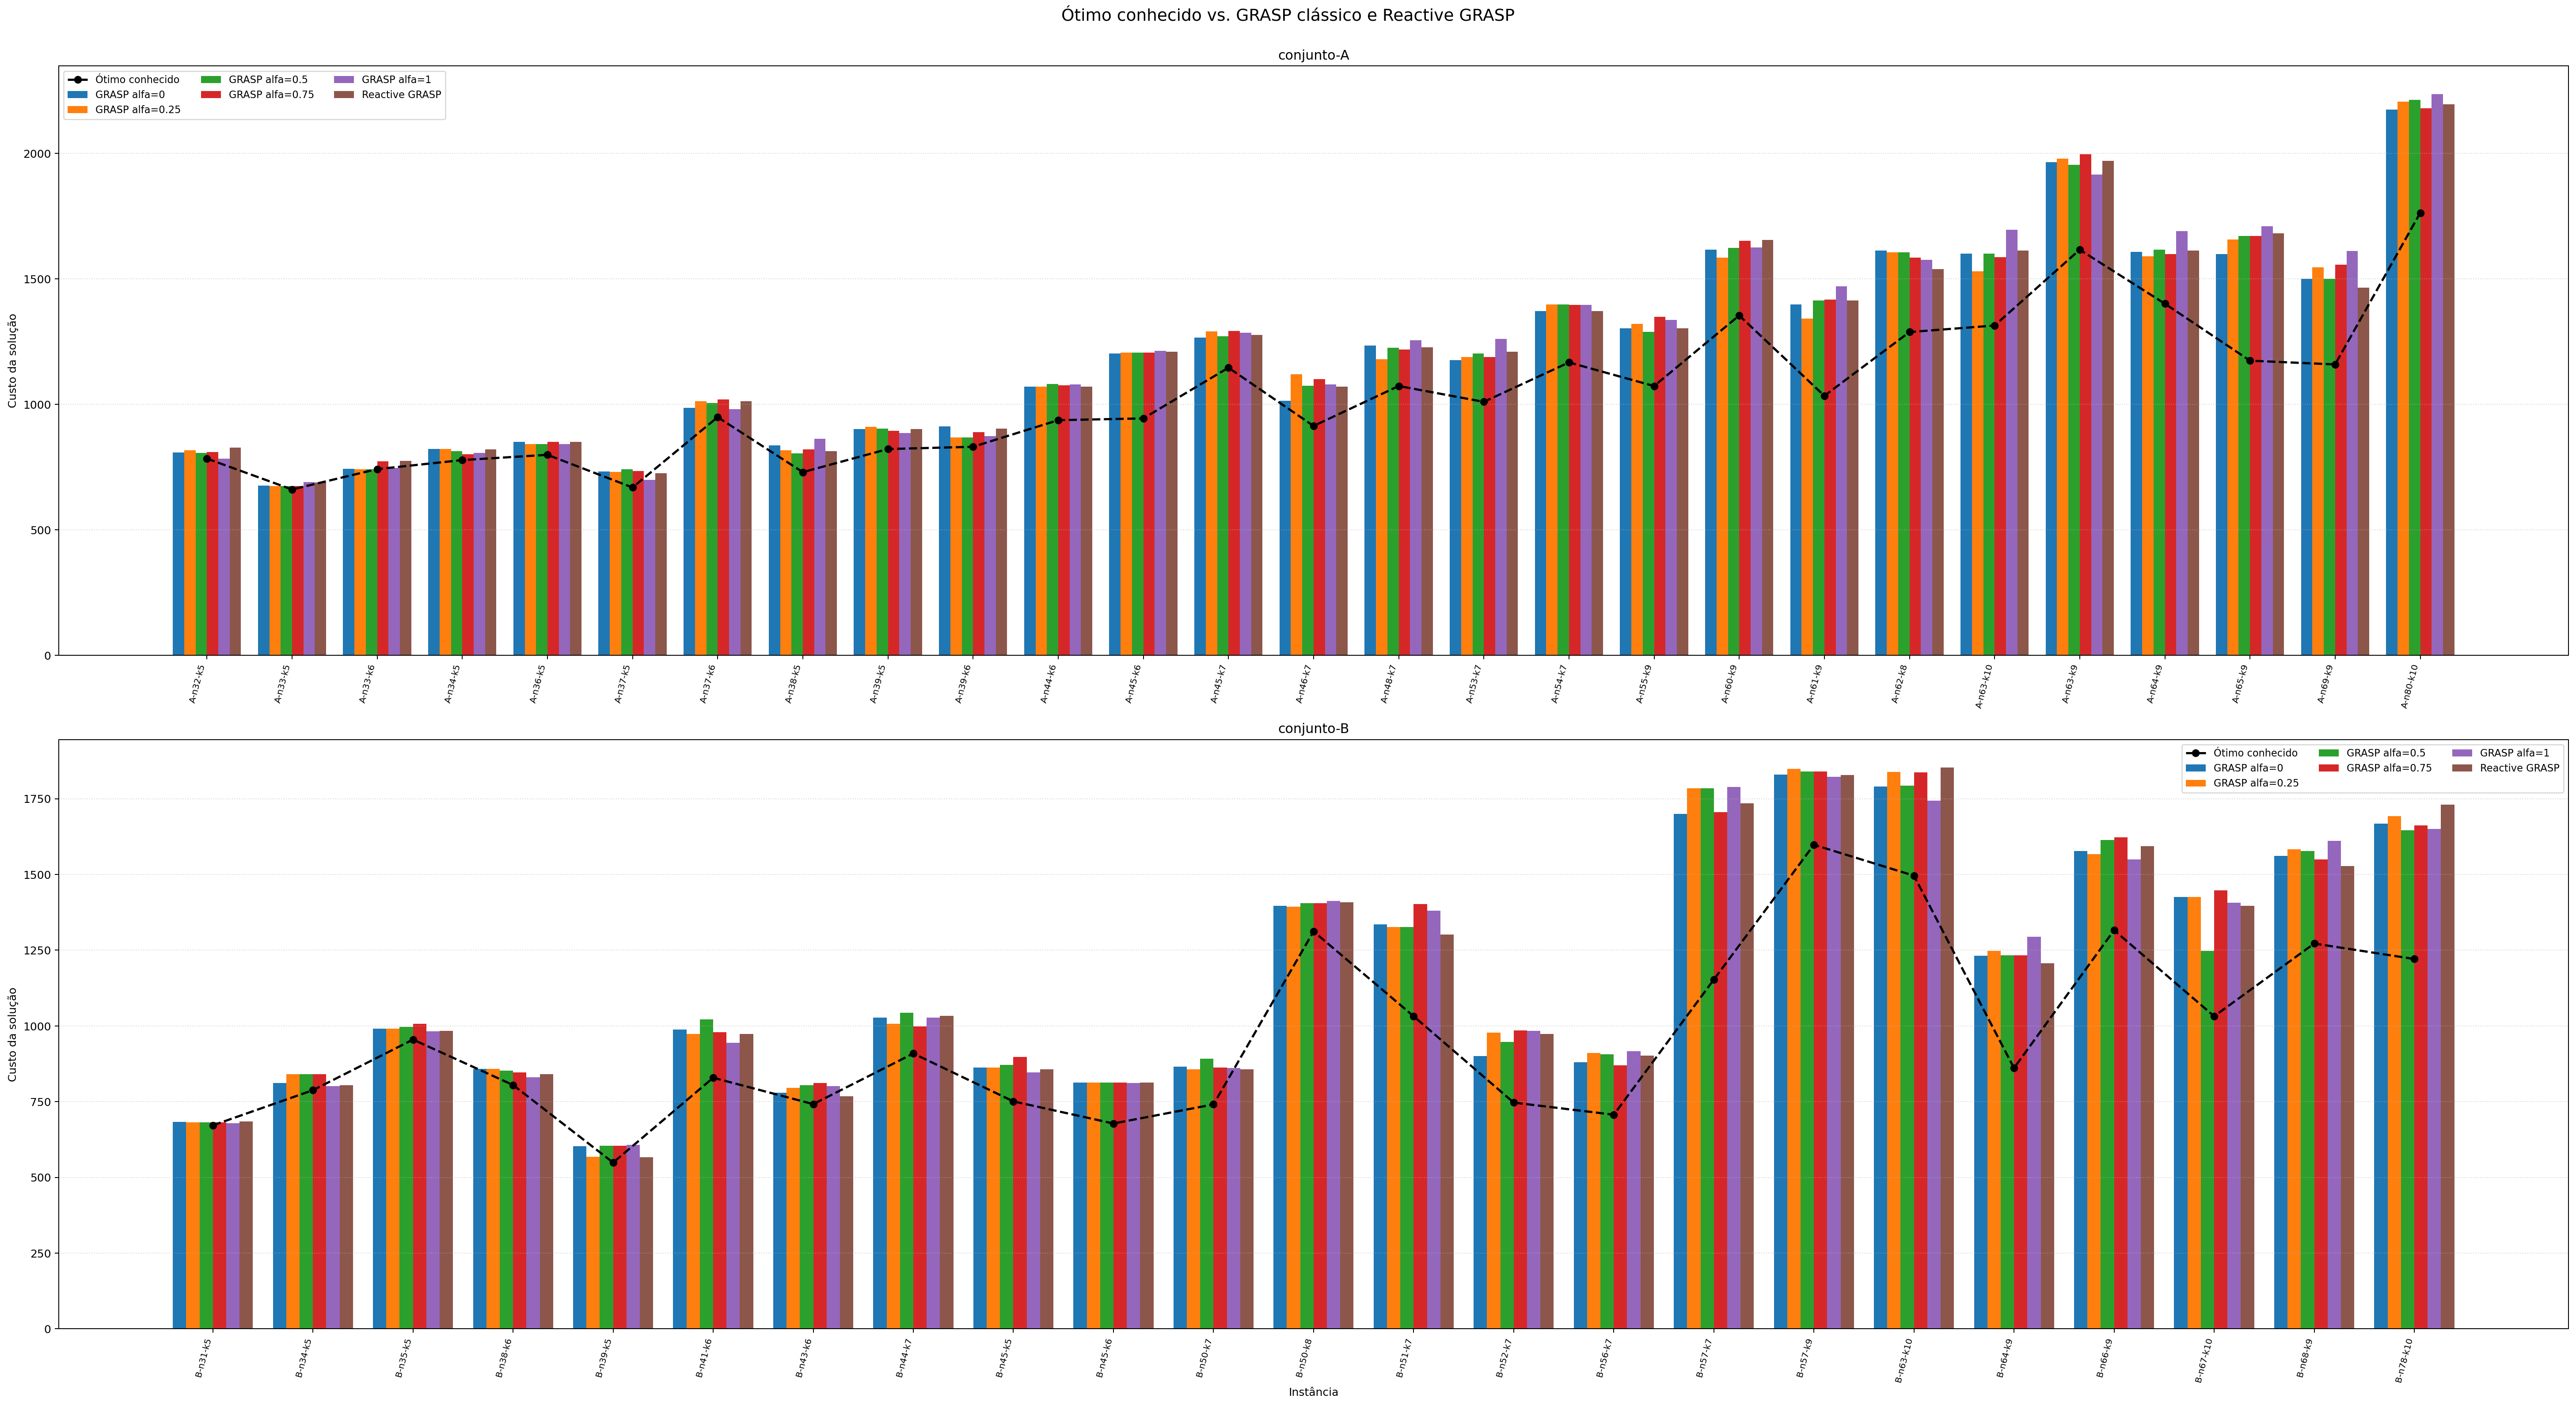

In [14]:
# Exibe inline no notebook o PNG salvo pela célula anterior.
from IPython.display import Image, display

display(Image(filename=str(arquivo_grafico), width=1200))